# 08 — Publicar, aprovar, descobrir e invocar na AWS

Comece pela arquitetura e pelos objetivos. Nas etapas executáveis,
leia o código, observe a resposta da AWS e interprete as validações
antes de avançar.

Referência: [workshops AgentCore](https://github.com/awslabs/agentcore-samples/tree/main/06-workshops).

**Pré-requisitos:** uma conta AWS autorizada, região escolhida e o kernel
**Santander Workshop (.venv)** preparado por `scripts/setup.sh`.
Use seu ambiente de notebooks na AWS. Os serviços, ferramentas e agentes
desta jornada executam na AWS.

## Arquitetura desta aula

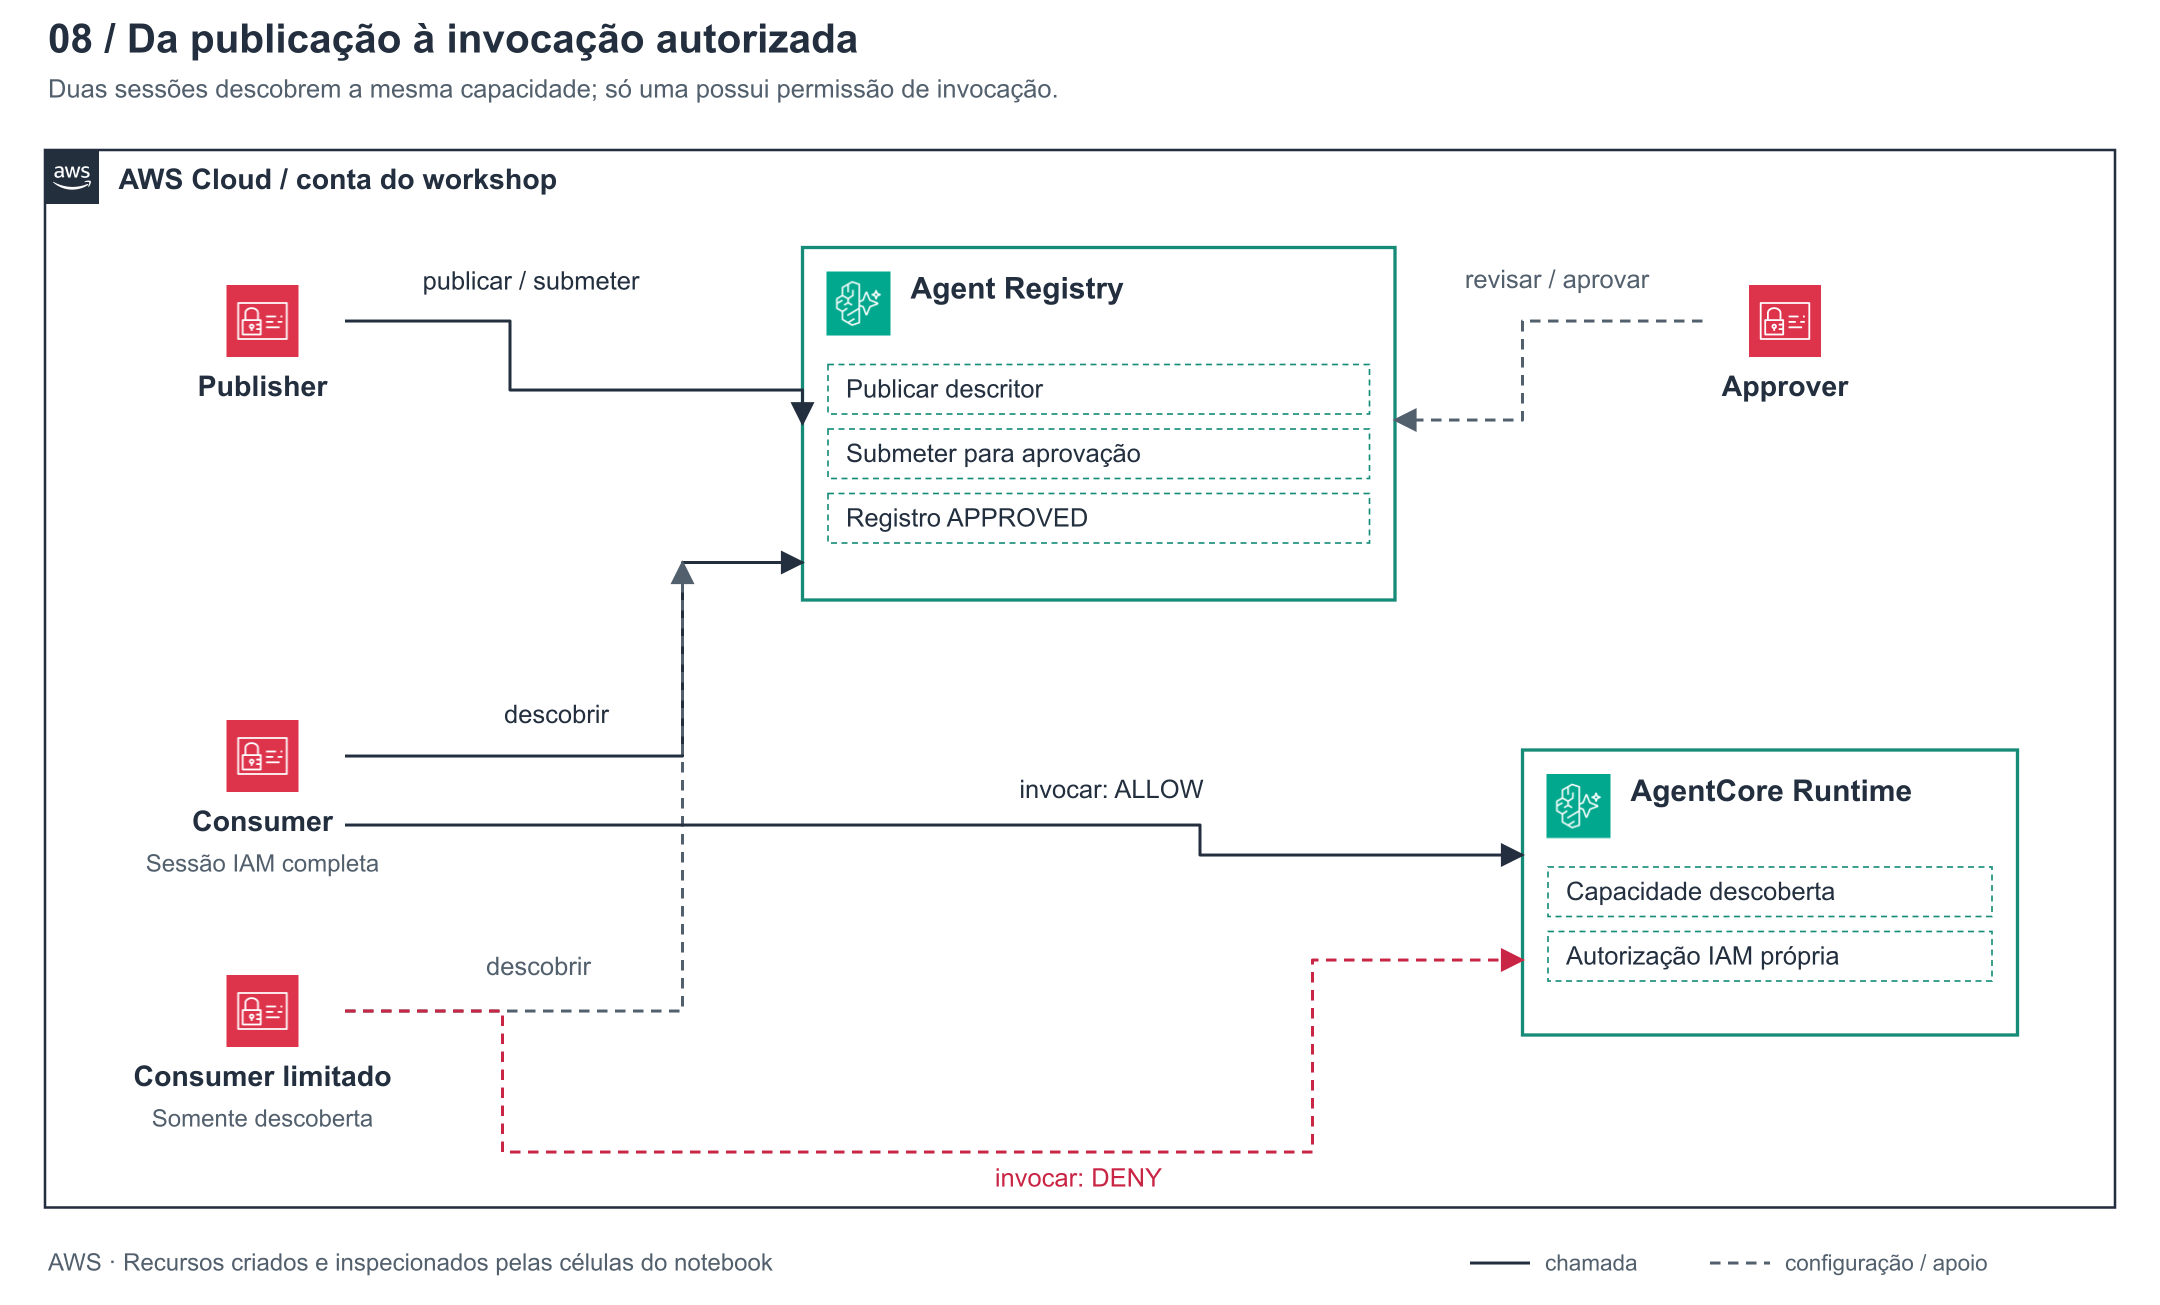

**Como ler o desenho:** A trilha de controle é Publisher → submissão → Approver → registro aprovado. A trilha de consumo é Consumer → descoberta → Runtime. A segunda seta exige autorização própria.

[Abrir PNG](../docs/diagramas/aulas/08.png) · [Abrir SVG](../docs/diagramas/aulas/08.svg)

## O que você vai aprender

**Pergunta da aula:** Como uma capacidade passa de rascunho a descoberta e depois a execução autorizada?

1. Publicar um descritor que corresponda ao servidor MCP implantado.
2. Submeter e aprovar o registro usando personas diferentes.
3. Descobrir e invocar como Consumer e repetir a descoberta sem permissão de invocação.

**Jornada SDK — uma conta AWS.** Os serviços são construídos pelas células; quando houver dependências de outra aula, elas estão indicadas abaixo.

**Antes de começar:** Aulas 03, 06 e 07 concluídas.

**O que esta aula cria ou remove:** Registro MCP versionado no Registry e suas transições de submissão/aprovação.

**O que reutiliza:** Runtime, Registry e as três personas IAM.

## Serviços AWS e suas responsabilidades

| Serviço | O que ele faz | Papel nesta aula |
|---|---|---|
| **Agent Registry** | Cataloga descritores de capacidades e controla publicação, aprovação e descoberta. Encontrar um endpoint no catálogo não concede permissão para invocá-lo. | Mantém o descritor, o estado de aprovação e a visão descobrível do registro. |
| **AWS Security Token Service (STS)** | Identifica o principal da sessão e emite credenciais temporárias ao assumir uma role. | Cria as sessões das personas, incluindo Consumer limitado por session policy. |
| **AWS Identity and Access Management (IAM)** | Controla quais ações uma identidade pode executar em quais recursos. A trust policy define quem pode assumir uma role; a policy de permissões define seu acesso. | Controla quem publica, aprova, descobre e invoca. |
| **Amazon Bedrock AgentCore Runtime** | Hospeda código de agentes ou servidores MCP com sessão, endpoint e role de execução. A identidade que invoca o endpoint é distinta da identidade usada pelo código hospedado. | Executa a ferramenta indicada pelo descritor aprovado. |

**Roteiro de execução:** leia a configuração e o código, execute a célula, aguarde o estado indicado e interprete a evidência antes de avançar. As seções **Validação** destacam chamadas e asserts já presentes na aula. Um erro inesperado não equivale a uma negativa autorizada esperada.

### Abrir uma sessão AWS e conferir a identidade

O SDK usa a sessão autorizada do seu ambiente AWS. STS informa quem está executando e em qual conta. A região é uma escolha da aula; ajuste-a antes de criar recursos. Nenhuma chave deve ser colada no notebook.

In [ ]:
import json
import os
import uuid
from pathlib import Path

import boto3
from IPython.display import display

REGION = boto3.Session().region_name or "us-west-2"
aws = boto3.Session(region_name=REGION)
sts = aws.client("sts")
identity = sts.get_caller_identity()
ACCOUNT_ID = identity["Account"]
expected_account = os.environ.get("WORKSHOP_EXPECTED_ACCOUNT")
if expected_account and ACCOUNT_ID != expected_account:
    raise RuntimeError(
        "WORKSHOP_ACCOUNT_MISMATCH: a sessão não corresponde à conta esperada."
    )
PARTITION = identity["Arn"].split(":")[1]
print({
    "account": ACCOUNT_ID,
    "region": REGION,
    "principal": identity["Arn"],
    "request_id": identity["ResponseMetadata"]["RequestId"],
})

### Registrar identificadores desta execução

As próximas aulas precisam lembrar os IDs retornados pelas chamadas de criação. Este registro contém apenas identificadores, está vinculado à conta/região e permite reiniciar o kernel. Ele é criado agora: você não precisa receber um arquivo privado do instrutor. O helper abaixo não chama AWS nem cria serviços.

In [ ]:
from santander_demo.notebook_state import NotebookState

ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "pyproject.toml").is_file()
)
state = NotebookState(
    ROOT / ".workshop", account_id=ACCOUNT_ID, region=REGION,
)
NAME_PREFIX = state.prefix
TAGS = state.tags
print({
    "execution": state.data["run_id"],
    "resource_name_prefix": NAME_PREFIX,
    "recorded_resources": sorted(state.data["resources"]),
    "execution_status": state.data.get("status", "ACTIVE"),
})

### Do catálogo até a chamada autorizada

`Developer → Publisher → Approver → Registry → Consumer → Runtime MCP`

**Pré-requisitos:** aulas 03, 06 e 07 na mesma execução, mais
`sts:AssumeRole` para as três roles registradas. A sessão autorizada
precisa corresponder ao principal confiável mostrado na aula 07.
Não alteramos trust policies para trocar de identidade durante a aula.

O Developer usa a sessão do editor para consultar a ferramenta; o Publisher cria e submete
seu registro; o Approver revisa o conteúdo; o Consumer descobre e invoca.
Depois, uma sessão limitada à descoberta encontra o mesmo registro,
mas recebe uma negativa ao invocar o Runtime.

Este exercício cataloga um **servidor MCP**, cuja ferramenta consulta
STS dentro da AWS. Ele não transforma o servidor em agente A2A nem
demonstra inferência de um modelo.

### Conferir as dependências e assumir as personas

STS emite credenciais temporárias para cada persona. Elas ficam somente na memória dos clientes boto3. Mostramos os ARNs das sessões; não exibimos nem registramos os valores das credenciais.

In [ ]:
import hashlib
import time
from urllib.parse import quote
from botocore.exceptions import ClientError

registry_entry = state.require("registry.instance", lesson="06")
runtime_entry = state.require("runtime.instance", lesson="03")
artifact_entry = state.require("runtime.artifact", lesson="03")
persona_entries = {
    name: state.require("registry.role." + name, lesson="07")
    for name in ("publisher", "approver", "consumer")
}
iam = aws.client("iam")
if ":assumed-role/" in identity["Arn"]:
    caller_role = identity["Arn"].split(":assumed-role/", 1)[1].split("/")[0]
    caller_principal = iam.get_role(RoleName=caller_role)["Role"]["Arn"]
else:
    caller_principal = identity["Arn"]
for entry in persona_entries.values():
    assert entry["trusted_principal"] == caller_principal, "PERSONA_PRINCIPAL_CHANGED"
    assert entry["registry_arn"] == registry_entry["arn"]
    assert entry["runtime_arn"] == runtime_entry["arn"]
    role = iam.get_role(RoleName=entry["name"])["Role"]
    assert role["Arn"] == entry["arn"] and not role.get("PermissionsBoundary")
    assert role["AssumeRolePolicyDocument"] == {
        "Version": "2012-10-17", "Statement": [{
            "Effect": "Allow", "Principal": {"AWS": caller_principal}, "Action": "sts:AssumeRole",
        }],
    }
    tags = {tag["Key"]: tag["Value"] for tag in role["Tags"]}
    assert all(tags.get(key) == value for key, value in TAGS.items())
    attached = iam.list_attached_role_policies(RoleName=entry["name"])
    assert not attached["AttachedPolicies"] and not attached.get("IsTruncated")
    inline = iam.list_role_policies(RoleName=entry["name"])
    assert inline["PolicyNames"] == [entry["policy_name"]] and not inline.get("IsTruncated")
    document = iam.get_role_policy(
        RoleName=entry["name"], PolicyName=entry["policy_name"],
    )["PolicyDocument"]
    assert hashlib.sha256(json.dumps(document, sort_keys=True).encode()).hexdigest() == (
        entry["policy_sha256"]
    ), "PERSONA_POLICY_CHANGED"
catalog_control = aws.client("agent-registry-control")
catalog = catalog_control.get_registry(registryId=registry_entry["id"])
assert catalog["status"] == "READY" and catalog["registryArn"] == registry_entry["arn"]
assert catalog["discoveryConfiguration"] == {"authorizerType": "AWS_IAM"}
assert not catalog.get("approvalConfiguration", {}).get("autoApprovalRules", [])
tags = catalog_control.list_tags_for_resource(resourceArn=registry_entry["arn"])["tags"]
assert all(tags.get(key) == value for key, value in TAGS.items())

DISCOVERY_ACTIONS = [
    "agent-registry:ListDiscoverableRegistryRecords",
    "agent-registry:GetDiscoverableRegistryRecord",
    "agent-registry:SearchDiscoverableRegistryRecords",
]

def assume_persona(name, discovery_only=False):
    args = {
        "RoleArn": persona_entries[name]["arn"],
        "RoleSessionName": NAME_PREFIX + "-" + name,
        "DurationSeconds": 900,
    }
    if discovery_only:
        assert name == "consumer"
        args["Policy"] = json.dumps({
            "Version": "2012-10-17", "Statement": [{
                "Effect": "Allow", "Action": DISCOVERY_ACTIONS,
                "Resource": [registry_entry["arn"], registry_entry["arn"] + "/record/*"],
            }],
        })
    assumed = sts.assume_role(**args)
    credentials = assumed["Credentials"]
    session = boto3.Session(
        aws_access_key_id=credentials["AccessKeyId"],
        aws_secret_access_key=credentials["SecretAccessKey"],
        aws_session_token=credentials["SessionToken"], region_name=REGION,
    )
    print({
        "persona": name, "discovery_only": discovery_only,
        "principal": assumed["AssumedRoleUser"]["Arn"],
        "request_id": assumed["ResponseMetadata"]["RequestId"],
    })
    return session

sessions = {name: assume_persona(name) for name in persona_entries}
developer = aws.client("bedrock-agentcore-control")
publisher = sessions["publisher"].client("agent-registry-control")
approver = sessions["approver"].client("agent-registry-control")
discovery = sessions["consumer"].client("agent-registry")
current = developer.get_agent_runtime(agentRuntimeId=runtime_entry["id"])
assert current["status"] == "READY" and current["agentRuntimeArn"] == runtime_entry["arn"]
assert current["roleArn"] == runtime_entry["role_arn"]
assert current["protocolConfiguration"] == {"serverProtocol": "MCP"}
assert not current.get("authorizerConfiguration"), "IAM_RUNTIME_REQUIRED"
RUNTIME_URL = (
    f"https://bedrock-agentcore.{REGION}.amazonaws.com/runtimes/"
    + quote(runtime_entry["arn"], safe="") + "/invocations?qualifier=DEFAULT"
)

### Consultar o servidor implantado como Developer

Initialize e tools/list são chamadas reais ao Runtime, assinadas pela sessão do editor (Developer). O descritor virá desta resposta. O parser confere a mensagem JSON-RPC e não aceita erros MCP como sucesso.

In [ ]:
initialize = {
    "jsonrpc": "2.0", "id": 1, "method": "initialize",
    "params": {"protocolVersion": "2025-03-26", "capabilities": {},
               "clientInfo": {"name": "santander-registry", "version": "1"}},
}

def invoke_mcp(client, session_id, request):
    response = client.invoke_agent_runtime(
        agentRuntimeArn=runtime_entry["arn"], runtimeSessionId=session_id,
        qualifier="DEFAULT", contentType="application/json",
        accept="application/json, text/event-stream", payload=json.dumps(request).encode(),
    )
    raw = response["response"].read().decode()
    if response["contentType"].startswith("text/event-stream"):
        messages = []
        for block in raw.replace("\r\n", "\n").split("\n\n"):
            data = [line[5:].lstrip() for line in block.splitlines() if line.startswith("data:")]
            if data:
                messages.append(json.loads("\n".join(data)))
        matched = [message for message in messages if message.get("id") == request["id"]]
        assert len(matched) == 1, "EXPECTED_ONE_MCP_RESPONSE"
        message = matched[0]
    else:
        message = json.loads(raw)
    assert message["id"] == request["id"] and "error" not in message, "MCP_REQUEST_FAILED"
    assert response["ResponseMetadata"]["RequestId"]
    print({"method": request["method"], "runtime_request_id": response["ResponseMetadata"]["RequestId"]})
    return message["result"]

def stop_session(client, session_id):
    try:
        response = client.stop_runtime_session(
            agentRuntimeArn=runtime_entry["arn"], runtimeSessionId=session_id, qualifier="DEFAULT",
        )
        print({"runtime_session": "STOPPED", "request_id": response["ResponseMetadata"]["RequestId"]})
    except client.exceptions.ResourceNotFoundException as error:
        print({"runtime_session": "ALREADY_TERMINATED_OR_NOT_FOUND",
               "request_id": error.response["ResponseMetadata"]["RequestId"]})

developer_api = aws.client("bedrock-agentcore")
developer_session_id = str(uuid.uuid4())
invoke_mcp(developer_api, developer_session_id, initialize)
tool_list = invoke_mcp(developer_api, developer_session_id, {
    "jsonrpc": "2.0", "id": 2, "method": "tools/list", "params": {},
})
stop_session(developer_api, developer_session_id)
assert [tool["name"] for tool in tool_list["tools"]] == ["workload_identity"]
print(json.dumps(tool_list, indent=2))

### Escrever e publicar o descritor como Publisher

CreateRegistryRecord recebe o descritor MCP e a lista real de ferramentas. Publicamos os metadados diretamente, sem instruir o Registry a buscar um endpoint protegido. O registro DRAFT ainda precisa de revisão. Guardamos o ARN retornado, nome e hash para conferir retomadas e a limpeza.

In [ ]:
PACKAGE_FIELDS = ("name", "recordType", "recordVersion", "description", "descriptors")
PACKAGE = {
    "name": NAME_PREFIX + "-workload-mcp",
    "recordType": "MCP", "recordVersion": "1.0.0",
    "description": "Servidor MCP sintetico: identidade IAM do workload na AWS",
    "descriptors": {"mcpServer": {
        "data": json.dumps({
            "name": "santander/workload-identity-" + state.data["run_id"],
            "description": "Consulta STS dentro do AgentCore Runtime",
            "version": "1.0.0",
            "remotes": [{"type": "streamable-http", "url": RUNTIME_URL}],
        }),
        "dataSchemaVersion": "2025-12-11",
        "additionalData": {"tools": {
            "data": json.dumps(tool_list), "dataSchemaVersion": "2025-11-25",
        }},
    }},
}
package_hash = hashlib.sha256(json.dumps(PACKAGE, sort_keys=True).encode()).hexdigest()
print(json.dumps(PACKAGE, indent=2))
record_entry = state.get("registry.record.mcp")
if record_entry is None:
    created = publisher.create_registry_record(
        registryId=registry_entry["id"], **PACKAGE,
        clientToken=str(uuid.uuid5(uuid.NAMESPACE_URL, NAME_PREFIX + ":record:mcp:1.0.0")),
    )
    record_entry = state.record("registry.record.mcp", {
        "arn": created["recordArn"], "id": created["recordArn"].rsplit("/", 1)[1],
        "registry_id": registry_entry["id"], "registry_arn": registry_entry["arn"],
        "name": PACKAGE["name"], "package_sha256": package_hash,
        "runtime_arn": runtime_entry["arn"], "runtime_source_sha256": artifact_entry["source_hash"],
    }, lesson="08")
assert record_entry["package_sha256"] == package_hash, "RECORD_PACKAGE_CHANGED"
assert record_entry["runtime_source_sha256"] == artifact_entry["source_hash"]
assert record_entry["runtime_arn"] == runtime_entry["arn"]
assert record_entry["registry_id"] == registry_entry["id"]
RECORD_ARGS = {"registryId": registry_entry["id"], "recordId": record_entry["id"]}

def reviewed_record(client):
    response = client.get_registry_record(**RECORD_ARGS)
    assert response["recordArn"] == record_entry["arn"]
    assert response["registryArn"] == registry_entry["arn"]
    actual = {key: response[key] for key in PACKAGE_FIELDS}
    assert hashlib.sha256(json.dumps(actual, sort_keys=True).encode()).hexdigest() == package_hash, (
        "RECORD_REVIEW_CHANGED"
    )
    return response

deadline = time.monotonic() + 180
while True:
    current = publisher.get_registry_record(**RECORD_ARGS)
    if current["status"] in {"DRAFT", "PENDING_APPROVAL", "APPROVED"}:
        current = reviewed_record(publisher)
        break
    assert current["status"] == "CREATING", ("RECORD_CREATION_FAILED", current["status"])
    if time.monotonic() >= deadline:
        raise TimeoutError("RECORD_NOT_READY")
    time.sleep(3)
print({"record_id": record_entry["id"], "status": current["status"],
       "request_id": current["ResponseMetadata"]["RequestId"]})

### Submeter o rascunho e verificar a separação de papéis

DRAFT e PENDING_APPROVAL não devem aparecer na descoberta. O Publisher submete seu registro, mas a tentativa de aprová-lo deve receber AccessDenied. A revisão e a aprovação pertencem à sessão Approver. Na retomada de um registro já aprovado, as verificações de conteúdo continuam obrigatórias.

In [ ]:
def discover_all(client):
    args = {"registryId": registry_entry["id"], "maxResults": 100}
    records = []
    while True:
        page = client.list_discoverable_registry_records(**args)
        assert page["ResponseMetadata"]["RequestId"]
        records.extend(page["registryRecords"])
        if not page.get("nextToken"):
            return records
        args["nextToken"] = page["nextToken"]

current = reviewed_record(publisher)
if current["status"] != "APPROVED":
    assert record_entry["id"] not in {record["recordId"] for record in discover_all(discovery)}
    print({"unapproved_record": "NOT_DISCOVERABLE"})
    if current["status"] == "DRAFT":
        submitted = publisher.submit_registry_record_for_approval(**RECORD_ARGS)
        print({"submission": submitted["status"],
               "request_id": submitted["ResponseMetadata"]["RequestId"]})
    deadline = time.monotonic() + 120
    while reviewed_record(publisher)["status"] != "PENDING_APPROVAL":
        if time.monotonic() >= deadline:
            raise TimeoutError("RECORD_SUBMISSION_TIMEOUT")
        time.sleep(3)
    try:
        publisher.update_registry_record_status(
            **RECORD_ARGS, status="APPROVED",
            statusReason="Teste negativo: Publisher nao deve aprovar",
        )
    except ClientError as error:
        assert error.response["Error"]["Code"] == "AccessDeniedException"
        assert error.response["ResponseMetadata"]["HTTPStatusCode"] == 403
        assert error.response["ResponseMetadata"]["RequestId"]
        print({"publisher_approval": "DENY",
               "request_id": error.response["ResponseMetadata"]["RequestId"]})
    else:
        raise AssertionError("PUBLISHER_APPROVED_OWN_RECORD")

### Revisar o conteúdo e aprovar como Approver

A revisão compara todos os campos publicados ao pacote esperado, inclusive endpoint e ferramentas. Só então UpdateRegistryRecordStatus aprova o registro. Uma mudança de conteúdo interrompe a célula.

### Validação — aprovação do descritor

A célula abaixo executa as verificações deste ponto. Compare sua saída com os critérios antes de continuar.

| Caso observado | Resultado esperado | O que comprova |
|---|---|---|
| Conteúdo revisado | Descritor corresponde ao Runtime e à ferramenta | A revisão aprova a capacidade realmente implantada. |
| Transição como Approver | Estado `APPROVED` | O registro pode entrar na descoberta. |

In [ ]:
current = reviewed_record(approver)
if current["status"] != "APPROVED":
    assert current["status"] == "PENDING_APPROVAL"
    approved = approver.update_registry_record_status(
        **RECORD_ARGS, status="APPROVED",
        statusReason="Descritor MCP e hash revisados na aula 08",
    )
    print({"approval": approved["status"],
           "request_id": approved["ResponseMetadata"]["RequestId"]})
deadline = time.monotonic() + 120
while reviewed_record(approver)["status"] != "APPROVED":
    if time.monotonic() >= deadline:
        raise TimeoutError("RECORD_APPROVAL_TIMEOUT")
    time.sleep(3)

### Leitura do resultado — aprovação do descritor

Leia o descritor antes de interpretar APPROVED. Aprovar um endpoint é uma decisão de governança sobre aquele registro; a execução continua dependendo de IAM.

### Descobrir e conferir o descritor como Consumer

A descoberta pode levar alguns segundos para indexar a aprovação. BatchGet devolve os descritores completos; não aceitamos respostas parciais nem um endpoint diferente do Runtime criado nesta execução. O catálogo contém metadados e não é a fonte das credenciais.

In [ ]:
deadline = time.monotonic() + 180
while record_entry["id"] not in {record["recordId"] for record in discover_all(discovery)}:
    if time.monotonic() >= deadline:
        raise TimeoutError("APPROVED_RECORD_NOT_DISCOVERABLE")
    time.sleep(3)
discovered = discovery.batch_get_discoverable_registry_record(
    entries=[{"registryId": registry_entry["id"], "recordIds": [record_entry["id"]]}],
)
assert not discovered["errors"] and len(discovered["registryRecords"]) == 1
record = discovered["registryRecords"][0]
assert record["recordId"] == record_entry["id"] and record["recordArn"] == record_entry["arn"]
assert record["registryArn"] == registry_entry["arn"] and record["status"] == "APPROVED"
actual = {key: record[key] for key in PACKAGE_FIELDS}
assert hashlib.sha256(json.dumps(actual, sort_keys=True).encode()).hexdigest() == package_hash, (
    "UNTRUSTED_DISCOVERY_DESCRIPTOR"
)
print({"discovery": "APPROVED_DESCRIPTOR_VERIFIED",
       "request_id": discovered["ResponseMetadata"]["RequestId"]})

### Invocar o Runtime com a sessão Consumer

A invocação é assinada pela persona Consumer; a ferramenta roda com a role do Runtime. O SDK usa o ARN conferido da execução, depois de validar o descritor. Não seguimos URLs arbitrárias retornadas pelo catálogo.

In [ ]:
consumer_api = sessions["consumer"].client("bedrock-agentcore")
consumer_session_id = str(uuid.uuid4())
invoke_mcp(consumer_api, consumer_session_id, initialize)
result = invoke_mcp(consumer_api, consumer_session_id, {
    "jsonrpc": "2.0", "id": 3, "method": "tools/call",
    "params": {"name": "workload_identity", "arguments": {}},
})
assert not result.get("isError"), "RUNTIME_TOOL_FAILED"
data = result.get("structuredContent")
if data is None:
    texts = [item["text"] for item in result["content"] if item["type"] == "text"]
    assert len(texts) == 1
    data = json.loads(texts[0])
assert data["execution"] == "AWS_AGENTCORE_RUNTIME"
assert data["account"] == ACCOUNT_ID and data["run_id"] == state.data["run_id"]
assert (":assumed-role/" + NAME_PREFIX + "-runtime/") in data["principal"]
assert data["sts_request_id"]
print({"consumer_invocation": "PASS", "result": data})
stop_session(consumer_api, consumer_session_id)

### Comprovar que descobrir não autoriza invocar

Uma session policy limita uma nova sessão Consumer às ações de descoberta. Ela não altera a role. A consulta continua funcionando, mas InvokeAgentRuntime precisa retornar uma negativa IAM real, com Request ID. Timeout e falha interna não contam como aceite.

### Validação — descoberta sem invocação

A célula abaixo executa as verificações deste ponto. Compare sua saída com os critérios antes de continuar.

| Caso observado | Resultado esperado | O que comprova |
|---|---|---|
| Consumer limitado / descoberta | Registro aprovado continua visível | A session policy preserva a descoberta. |
| Mesma sessão / invocação | `discovery_only_invocation: DENY` | Conhecer o endpoint não concede InvokeAgentRuntime. |

In [ ]:
limited = assume_persona("consumer", discovery_only=True)
limited_discovery = limited.client("agent-registry")
assert record_entry["id"] in {record["recordId"] for record in discover_all(limited_discovery)}
try:
    limited.client("bedrock-agentcore").invoke_agent_runtime(
        agentRuntimeArn=runtime_entry["arn"], runtimeSessionId=str(uuid.uuid4()),
        qualifier="DEFAULT", contentType="application/json",
        accept="application/json, text/event-stream", payload=json.dumps(initialize).encode(),
    )
except ClientError as error:
    assert error.response["Error"]["Code"] == "AccessDeniedException"
    assert error.response["ResponseMetadata"]["HTTPStatusCode"] == 403
    assert error.response["ResponseMetadata"]["RequestId"]
    print({"discovery_only_invocation": "DENY",
           "request_id": error.response["ResponseMetadata"]["RequestId"]})
else:
    raise AssertionError("DISCOVERY_ONLY_SESSION_INVOKED_RUNTIME")

### Leitura do resultado — descoberta sem invocação

Este contraexemplo isola a permissão de execução. A chamada anterior com Consumer completo mostra que o Runtime funciona; o DENY da sessão limitada decorre de IAM.

### O que observar e como encerrar

A publicação, submissão, aprovação, descoberta e invocação ocorreram
nos serviços AWS, sob sessões distintas. O Publisher não aprovou seu
próprio registro. A sessão com acesso apenas ao catálogo não conseguiu
invocar o Runtime.

Em uma empresa, a atribuição das personas precisa refletir a segregação
entre pessoas e workloads; nesta aula, um participante assume todas
elas para demonstrar o fluxo.

A aula 99 primeiro confere e remove este registro, depois as personas,
Registry e Runtime. Um registro desconhecido impede a limpeza.

## Análise dos resultados

Publicação e aprovação controlam o catálogo; a autorização do endpoint controla o uso. O descritor revisado liga o que foi descoberto à ferramenta que efetivamente executa na AWS.

**Evidência e alcance:** O [aceite AWS de 05/11/2026](../docs/aceite-notebooks-sdk.md) registra a execução bem-sucedida desta aula, incluindo o ciclo de limpeza e reconstrução. Esse histórico é uma referência; os outputs e Request IDs gerados agora são a evidência da sua conta e da sua execução.

**Limites da demonstração:** As permissões são específicas desta capacidade. A retomada pode encontrar um registro já aprovado; isso não representa uma nova aprovação organizacional.

**Para discutir:** Qual evidência separa um problema de descoberta de uma negativa de invocação?

**Registro da aula:** anote conta/região, run_id quando disponível, casos permitidos/negados e IDs de requisição. Preserve a mensagem de uma falha inesperada; não publique tokens, senhas ou credenciais nas saídas. Os notebooks do repositório são distribuídos sem outputs.